# Kernel SVM (SMO)

The linear SVM (`16_svm`) can only draw straight boundaries. The **kernel trick** fixes that: replace every dot product `x·x'` with a kernel `k(x, x')` that equals a dot product in some much richer feature space — without ever constructing that space.

| Kernel | `k(x, x')` | Boundary |
|---|---|---|
| `linear` | `x·x'` | straight line |
| `poly` | `(γ·x·x' + 1)^degree` | polynomial curve |
| `rbf` | `exp(−γ‖x − x'‖²)` | flexible, local — larger `γ` means wigglier |

## Dual form and SMO

Instead of learning `w`, the dual learns one multiplier `alpha_i` per training point (`0 ≤ alpha ≤ C`, `Σ alpha·y = 0`). Points with `alpha > 0` are the **support vectors**, and prediction uses only them:

```
f(x) = Σ alpha_i · y_i · k(x_i, x) + b
```

**SMO** solves the dual by repeatedly choosing two multipliers and optimizing just those two analytically (the equality constraint forces them to move together), until no point violates the KKT conditions by more than `tol`. This is a simplified version: the second multiplier is chosen at random rather than by a heuristic.

`C` is the penalty for margin violations (large = harder margin, risk of overfitting). Scale features first; `gamma` is on the scale of `1 / ‖x − x'‖²`.

## Usage

```python
# (the class is defined in the Implementation section below)

model = KernelSVM(kernel="rbf", C=1.0, gamma=1.0).fit(X_train, y_train)
preds = model.predict(X_test)
print(len(model.support_vectors_))
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _kernel(A, B, kind, gamma, degree):
    if kind == "linear":
        return A @ B.T
    if kind == "poly":
        return (gamma * (A @ B.T) + 1.0) ** degree
    if kind == "rbf":
        sq_dist = ((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2)
        return np.exp(-gamma * sq_dist)
    raise ValueError(f"unknown kernel: {kind}")


class KernelSVM:
    """Binary SVM in the dual form, trained with simplified SMO (Sequential Minimal Optimization).

    The kernel lets the SVM draw curved boundaries: it computes dot products in a high-dimensional
    feature space without ever building that space. Prediction only needs the support vectors:

        f(x) = sum_i alpha_i * y_i * k(x_i, x) + b

    SMO repeatedly picks two multipliers (alpha_i, alpha_j), solves that tiny 2-variable problem
    exactly, and moves on; sum(alpha * y) = 0 and 0 <= alpha <= C are kept throughout.

    ponytail: the partner j is picked at random (not by max |Ei - Ej|) and the full n x n kernel
    matrix is stored. Fine for a few thousand samples; swap in working-set selection for more."""

    def __init__(self, C=1.0, kernel="rbf", gamma=1.0, degree=3, tol=1e-3, max_passes=5,
                 max_iter=200, random_state=0):
        self.C = C
        self.kernel = kernel
        self.gamma = gamma
        self.degree = degree
        self.tol = tol
        self.max_passes = max_passes  # stop after this many full sweeps with no change
        self.max_iter = max_iter      # hard cap on sweeps, in case it never settles
        self.random_state = random_state
        self.classes_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("KernelSVM is binary: needs exactly 2 classes")
        y_pm = 2.0 * y_enc - 1.0

        n = len(X)
        K = _kernel(X, X, self.kernel, self.gamma, self.degree)
        rng = np.random.default_rng(self.random_state)
        alpha, b = np.zeros(n), 0.0
        C, tol = self.C, self.tol

        passes = sweeps = 0
        while passes < self.max_passes and sweeps < self.max_iter:
            changed = 0
            for i in range(n):
                E_i = (alpha * y_pm) @ K[:, i] + b - y_pm[i]  # prediction error on sample i
                # violates the KKT conditions? (inside the margin with room to move)
                if (y_pm[i] * E_i < -tol and alpha[i] < C) or (y_pm[i] * E_i > tol and alpha[i] > 0):
                    j = rng.choice(np.delete(np.arange(n), i))
                    E_j = (alpha * y_pm) @ K[:, j] + b - y_pm[j]
                    a_i_old, a_j_old = alpha[i], alpha[j]

                    # box that keeps alpha_j inside [0, C] while sum(alpha*y) stays fixed
                    if y_pm[i] != y_pm[j]:
                        L, H = max(0.0, a_j_old - a_i_old), min(C, C + a_j_old - a_i_old)
                    else:
                        L, H = max(0.0, a_i_old + a_j_old - C), min(C, a_i_old + a_j_old)
                    eta = 2 * K[i, j] - K[i, i] - K[j, j]  # curvature along the constraint line
                    if L == H or eta >= 0:
                        continue

                    a_j_new = np.clip(a_j_old - y_pm[j] * (E_i - E_j) / eta, L, H)
                    if abs(a_j_new - a_j_old) < 1e-5:
                        continue  # too small to matter; leave BOTH alphas untouched
                    alpha[j] = a_j_new
                    alpha[i] = a_i_old + y_pm[i] * y_pm[j] * (a_j_old - a_j_new)

                    b1 = b - E_i - y_pm[i] * (alpha[i] - a_i_old) * K[i, i] - y_pm[j] * (alpha[j] - a_j_old) * K[i, j]
                    b2 = b - E_j - y_pm[i] * (alpha[i] - a_i_old) * K[i, j] - y_pm[j] * (alpha[j] - a_j_old) * K[j, j]
                    b = b1 if 0 < alpha[i] < C else b2 if 0 < alpha[j] < C else (b1 + b2) / 2
                    changed += 1
            passes = passes + 1 if changed == 0 else 0
            sweeps += 1

        sv = alpha > 1e-8  # support vectors: the only points with non-zero alpha
        self.support_vectors_ = X[sv]
        self.dual_coef_ = (alpha * y_pm)[sv]
        self.bias = b
        self.alpha_ = alpha
        return self

    def decision_function(self, X):
        K = _kernel(np.asarray(X, dtype=float), self.support_vectors_, self.kernel, self.gamma, self.degree)
        return K @ self.dual_coef_ + self.bias

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

## See it work

### 1. A non-linear boundary from a linear algorithm

The kernel trick: instead of mapping points into a huge feature space, the SVM only needs similarities `k(a, b)`. With the RBF kernel it draws a curved boundary on moons. Circled points are the **support vectors**, the only training points kept in the model (`support_vectors_`).

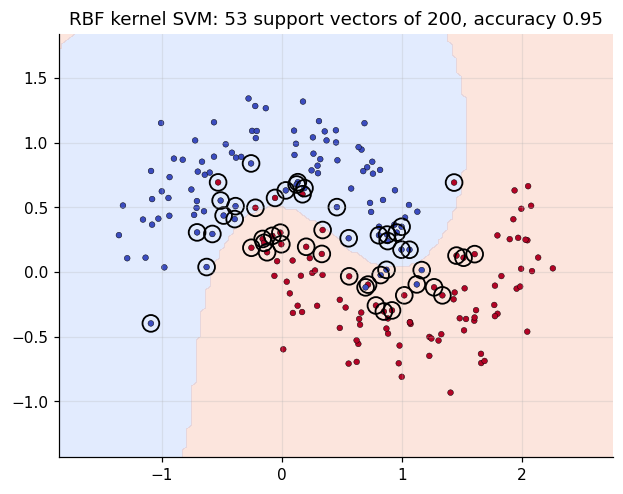

In [3]:
from sklearn.datasets import make_moons
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

X, y = make_moons(n_samples=200, noise=0.2, random_state=0)
m = KernelSVM(C=1.0, kernel="rbf", gamma=1.0).fit(X, y)
fig, ax = plt.subplots(figsize=(6.5, 5)); plot_boundary(ax, m, X, y, n=120)
ax.scatter(*m.support_vectors_.T, s=120, facecolors="none", edgecolors="k", linewidths=1.2)
ax.set_title(f"RBF kernel SVM: {len(m.support_vectors_)} support vectors of {len(X)}, accuracy {(m.predict(X) == y).mean():.2f}"); plt.show()

### 2. `gamma`: how local is the kernel?

`gamma` is the inverse width of the RBF bump around each support vector. Small: broad bumps, smooth and nearly linear (underfits). Large: tiny bumps, the boundary wraps around individual points (overfits).

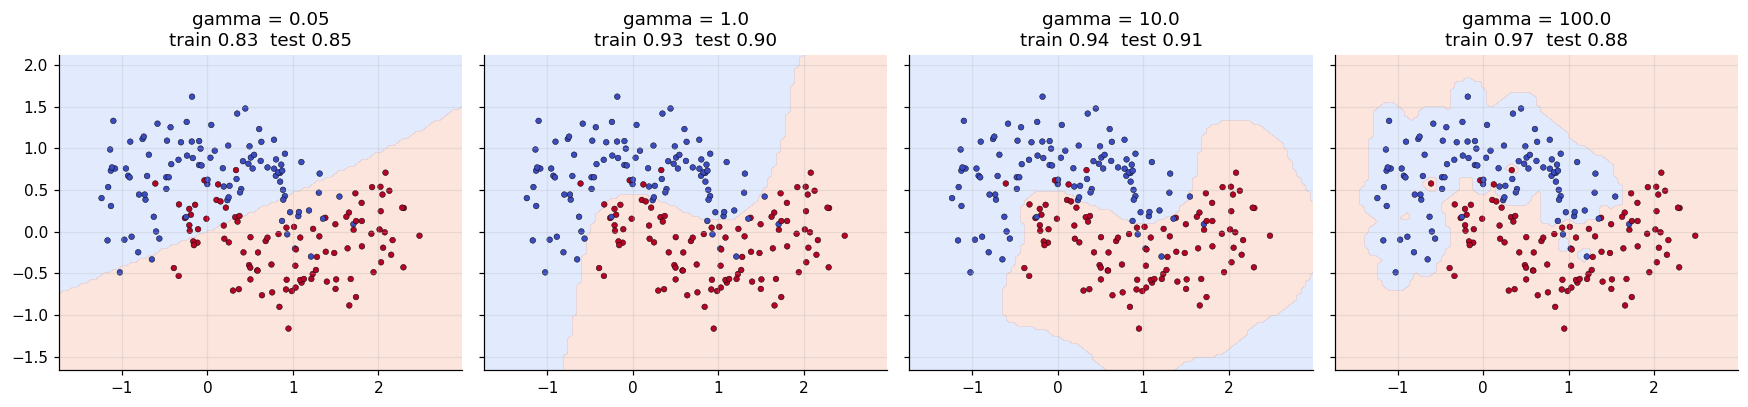

In [4]:
Xn, yn = make_moons(n_samples=200, noise=0.3, random_state=1)
Xt, yt = make_moons(n_samples=1000, noise=0.3, random_state=2)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, g in zip(axes, [0.05, 1.0, 10.0, 100.0]):
    mm = KernelSVM(C=1.0, kernel="rbf", gamma=g).fit(Xn, yn); plot_boundary(ax, mm, Xn, yn, n=90)
    ax.set_title(f"gamma = {g}\ntrain {(mm.predict(Xn) == yn).mean():.2f}  test {(mm.predict(Xt) == yt).mean():.2f}")
plt.tight_layout(); plt.show()

### 3. Choosing the kernel

Concentric circles: a linear kernel cannot do better than chance, a polynomial of degree 2 can (the boundary `x² + y² = r²` is quadratic), and RBF handles it easily.

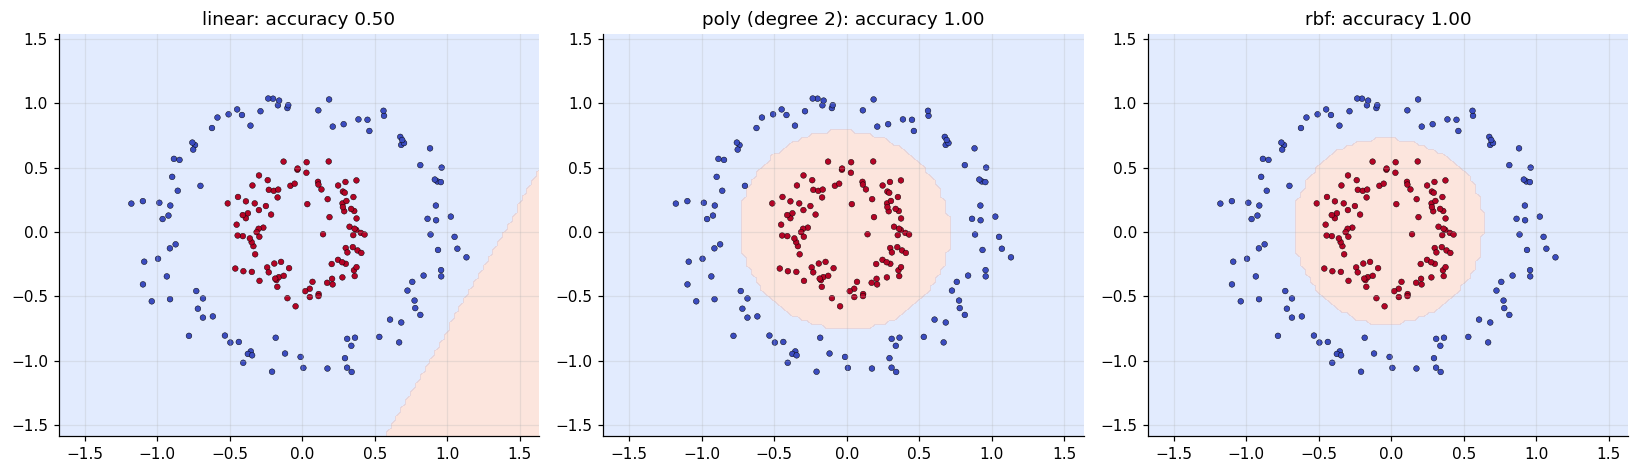

In [5]:
from sklearn.datasets import make_circles

Xc, yc = make_circles(n_samples=200, factor=0.4, noise=0.08, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (name, kw) in zip(axes, [("linear", dict(kernel="linear")), ("poly (degree 2)", dict(kernel="poly", degree=2, gamma=1.0)), ("rbf", dict(kernel="rbf", gamma=2.0))]):
    mm = KernelSVM(C=1.0, **kw).fit(Xc, yc); plot_boundary(ax, mm, Xc, yc, n=100); ax.set_title(f"{name}: accuracy {(mm.predict(Xc) == yc).mean():.2f}")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X, y = make_moons(n_samples=300, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

C, gamma = 1.0, 1.0
ours = KernelSVM(kernel="rbf", C=C, gamma=gamma).fit(X_train, y_train)
theirs = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("moons test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
print("support vectors: ours=%d sklearn=%d (of %d training points)"
      % (len(ours.support_vectors_), len(theirs.support_vectors_), len(X_train)))
assert abs(acc_ours - acc_theirs) < 0.03

linear = KernelSVM(kernel="linear", C=C).fit(X_train, y_train)
print("same data, linear kernel:   %.4f" % (linear.predict(X_test) == y_test).mean())

moons test accuracy: ours=1.0000 sklearn=1.0000
support vectors: ours=52 sklearn=51 (of 210 training points)
same data, linear kernel:   0.8556


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _circles(seed=0, n=200):
    # inner disc vs outer ring: impossible for any straight line
    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, 2 * np.pi, n)
    radius = np.where(np.arange(n) < n // 2, 1.0, 3.0) + rng.normal(scale=0.15, size=n)
    X = np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])
    y = np.where(np.arange(n) < n // 2, "inner", "outer")
    return X, y


def test_rbf_solves_circles_but_linear_kernel_cannot():
    X, y = _circles()
    rbf = KernelSVM(kernel="rbf", gamma=0.5, C=10.0).fit(X, y)
    linear = KernelSVM(kernel="linear", C=10.0).fit(X, y)
    assert (rbf.predict(X) == y).mean() > 0.97
    assert (linear.predict(X) == y).mean() < 0.75


def test_dual_constraints_hold():
    X, y = _circles(seed=1)
    model = KernelSVM(kernel="rbf", gamma=0.5, C=5.0).fit(X, y)
    assert (model.alpha_ >= -1e-9).all() and (model.alpha_ <= 5.0 + 1e-9).all()  # 0 <= alpha <= C
    assert abs(model.dual_coef_.sum()) < 1e-6                                     # sum(alpha * y) = 0


def test_only_support_vectors_are_kept():
    X, y = _circles(seed=2)
    model = KernelSVM(kernel="rbf", gamma=0.5, C=10.0).fit(X, y)
    assert 0 < len(model.support_vectors_) < len(X)


def test_rejects_multiclass():
    try:
        KernelSVM().fit(np.zeros((3, 2)), np.array([0, 1, 2]))
    except ValueError:
        return
    raise AssertionError("expected ValueError")

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_rbf_solves_circles_but_linear_kernel_cannot
PASS test_dual_constraints_hold


PASS test_only_support_vectors_are_kept
PASS test_rejects_multiclass

all 4 tests passed


## Takeaways

- **Use it** for small to medium data with non-linear structure and moderate dimension. It stores only support vectors, and prediction is `Σ αᵢ yᵢ k(xᵢ, x) + b`.
- **Training:** a simplified SMO solves the dual (`0 ≤ αᵢ ≤ C`, `Σ αᵢ yᵢ = 0`) by optimising two multipliers at a time. Cost is roughly between `O(n²)` and `O(n³)`, so it does not scale to huge `n`.
- **Knobs:** `C` (margin softness: large means fit the data harder) and `gamma` (locality). Tune both by cross-validation, and scale features.
- **Interview line:** *"Dual SVM with kernels: only support vectors have `α > 0`; the RBF kernel gives a smooth boundary whose complexity is set by `C` and `gamma`."*